# The book's GEMM kernels, in a simulator

A companion to Part III of [*Modern GPU Programming for MLSys*](https://mlc.ai/modern-gpu-programming-for-mlsys/)
for readers who do not have a Blackwell GPU. The book builds a half-precision GEMM for the B200 in
nine steps, `hgemm_v1` to `hgemm_v9`. This notebook runs each of them in
[warplens](../../README.md), a simulator that executes the kernel's PTX on the CPU, and looks at what a
simulator can show and a GPU cannot: the instructions the kernel became, which warp executed which of
them and in what order, what the protocol checkers have to say, where results sit in tensor memory, and
an approximate account of where time goes.

Read it next to the book. The explanations of *why* each kernel is written the way it is are the
book's; this notebook does not repeat them.

**What you need**

- warplens installed from a checkout of its repository (this notebook uses `examples/08_book/run.py`
  and `examples/08_book/booksim.py` from it), on Linux, with a C compiler and the CUDA toolkit headers;
- `pip install apache-tvm-tirx cuda-bindings`, and an NVRTC that knows `sm_100a` (CUDA 12.8 or newer);
- **your own clone of the book**. Its repository has no license, so none of its code is in this
  notebook or in warplens. The kernels are read from your clone when a cell runs, and no cell prints
  them.

No GPU is used, and none is needed.

**How the notebook runs a kernel**

The book's kernels are TIRx programs. TIRx compiles them with NVRTC and launches them through the CUDA
driver. `warplens run python script.py` handles such a program by starting it as a child process with
a small shim library in place of the CUDA runtime; every `cudaMalloc`, tensor-map encoding and kernel
launch of the child is served by the simulator in the parent. Three ways to use that from a notebook
were considered:

1. *Call `warplens run` as a subprocess and read its output.* Simple, but all that comes back is text:
   one line per launch and the findings.
2. *Keep the PTX (`WARPLENS_DUMP_PTX`) and launch it again in this process with `warplens.Device`.*
   That needs the kernel's arguments, and from `hgemm_v4` on those are tensor maps passed by value,
   which only TIRx's runtime knows how to build.
3. *Let this process play the part of `warplens run`.* `booksim.simulate()` starts the child with the
   shim, exactly as the command does, and serves its calls here with the same class the command uses
   (`warplens.host.shim_server.ShimServer`). The launch statistics, findings, timing reports and the
   parsed PTX then stay in this process as Python objects, and a `trace` callback can watch every
   instruction.

This notebook uses the third. The kernel's host side still runs in a child process, one per kernel, so
TVM and the CUDA shim never load into the notebook's own process, and a failure in one kernel does not
disturb the rest. Each run compiles the kernel from scratch and takes about ten seconds; the whole
notebook takes about two minutes.

**How far to trust what you see**

- warplens has not been compared with a Blackwell GPU. Its model of TMA, mbarriers, `tcgen05` and
  tensor memory comes from the PTX specification and from CUTLASS, and the evidence for it is that
  real kernels, these nine among them, compute the right result in it.
- **The timing model is uncalibrated.** Several of its parameters are assumptions. Its output explains
  a mechanism under stated parameters; it is not a prediction of time on a B200. Every timing figure
  below carries that caveat.
- The order in which warps take their steps is the simulator's scheduler's, one of many orders that
  hardware could produce.

The [user guide](../../docs/guide.md) has the details.

## Setup

Point `BOOK` at your clone, either with the environment variable `WARPLENS_BOOK` or by editing the
marked line.

In [1]:
import os
import re
import sys
from pathlib import Path

# ----- EDIT THIS (or set WARPLENS_BOOK): the path to your clone of the book ---------------------
#   git clone https://github.com/mlc-ai/modern-gpu-programming-for-mlsys
BOOK = Path(os.environ.get("WARPLENS_BOOK", "~/modern-gpu-programming-for-mlsys")).expanduser()
# ------------------------------------------------------------------------------------------------

CHAPTERS = ["chapter_gemm_basics", "chapter_gemm_async", "chapter_gemm_advanced"]
assert all((BOOK / c / "index.md").is_file() for c in CHAPTERS), \
    "BOOK is not a clone of the book: set WARPLENS_BOOK or edit the line above"

here = Path.cwd() if (Path.cwd() / "booksim.py").is_file() else Path.cwd() / "examples" / "08_book"
sys.path.insert(0, str(here))  # booksim.py lives next to this notebook

import booksim
import warplens
from warplens.viz import timeline_svg, tmem

found = {c: re.findall(r"^def (hgemm_v\d+)\(", (BOOK / c / "index.md").read_text(), flags=re.M) for c in CHAPTERS}
print("warplens", warplens.__version__)
for chapter, kernels in found.items():
    print(f"  {chapter}: {', '.join(kernels)}")

warplens 0.0.1
  chapter_gemm_basics: hgemm_v1, hgemm_v2, hgemm_v3
  chapter_gemm_async: hgemm_v4, hgemm_v5, hgemm_v6
  chapter_gemm_advanced: hgemm_v7, hgemm_v8, hgemm_v9


`run()` below is what every section starts with. It compiles one kernel from your clone, runs it on an
M x N x K problem with the timing model on and a `Watch` attached, and prints the two facts
everything else builds on: that the result matched NumPy (the check is the runner's, with the book's
tolerances), and what was launched.

In [2]:
launches = {}  # version -> the launch, kept for the comparison at the end


def run(version, size=None, **options):
    watch = booksim.Watch(ctas=[(0, 0, 0), (1, 0, 0)])
    done = booksim.run_book_kernel(BOOK, version, size, timing=options.pop("timing", True), trace=watch, **options)
    launch = launches[version] = done.launch
    print(done.stdout.strip())
    print(booksim.launch_line(launch))
    return launch, watch

## Chapter "Building a Tiled GEMM"

### Step 1: one tile (`hgemm_v1`)

One CTA of 128 threads computes one 128 x 128 tile from K = 64 columns of A and B.

In [3]:
v1, watch1 = run("v1")

hgemm_v1 128x128x64: matches NumPy (max error 0.0156, 0.3 s)
grid (1, 1, 1), block (128, 1, 1): 1 CTA(s), 4 warp(s), 33,792 bytes of shared memory per CTA
5,011 warp-instructions executed (158,386 counted per thread), 2 divergent branch(es), 0 finding(s)


**The PTX.** TIRx compiled the kernel to PTX for `sm_100a`, and that PTX is what ran. These are its
Blackwell-specific and synchronization instructions: how often each form appears in the text, and where.

In [4]:
print(booksim.key_instructions(v1))

607 PTX instructions for sm_100a; parameters: .u64, .u64, .u64
  count  first line  instruction
      3         340  bar.sync
      1         601  elect.sync
      1         338  fence.mbarrier_init.release.cluster
      2         335  fence.proxy.async.shared::cta
      2         341  ld.shared.b32
      1         325  mbarrier.init.shared.b64
      1         672  mbarrier.try_wait.parity.acquire.cta.shared::cta.b64
     32         360  st.shared.b16
      1         331  tcgen05.alloc.cta_group::1.sync.aligned.shared::cta.b32
      1         659  tcgen05.commit.cta_group::1.mbarrier::arrive::one.shared::cluster.b64
      1        1343  tcgen05.dealloc.cta_group::1.sync.aligned.b32
      1         680  tcgen05.fence::after_thread_sync
      1         683  tcgen05.ld.sync.aligned.32x32b.x128.b32
      4         621  tcgen05.mma.cta_group::1.kind::f16
      1        1338  tcgen05.relinquish_alloc_permit.cta_group::1.sync.aligned
      1         686  tcgen05.wait::ld.sync.aligned


Things to find in that list, and in the book's description of the kernel:

- `tcgen05.alloc` and `tcgen05.dealloc`: tensor memory is reserved and released explicitly.
- four `tcgen05.mma ... kind::f16`: one MMA covers K = 16 half-precision elements, and the tile has K = 64.
- `tcgen05.commit` and `mbarrier.try_wait`: the MMAs are asynchronous. The commit makes an mbarrier
  arrive when they are done, and the wait is how the threads learn of it.
- `tcgen05.ld ... 32x32b.x128`: every thread reads 128 accumulator columns of its own tensor-memory lane.
- the many `st.shared.b16`: A and B reach shared memory by ordinary loads and stores. That is what
  Step 4 replaces.

**Who did what.** A GPU gives you the result; the simulator also saw every instruction each warp
executed. Counted by kind, for the kernel's four warps:

In [5]:
print(watch1.roles())
print()
print(watch1.order())

CTA (0, 0, 0): instructions executed, by warp
  warp  mbarrier wait    MMA  MMA commit  TMEM load  TMEM alloc  TMEM dealloc  SMEM store  SMEM load  barrier  global load  global store
     0              2      4           1          1           1             1         128          2        3          128           128
     1              2      .           .          1           .             .         128          1        3          128           128
     2              2      .           .          1           .             .         128          1        3          128           128
     3              2      .           .          1           .             .         128          1        3          128           128

CTA (0, 0, 0): first 16 of 16 asynchronous steps, in the order this run's scheduler took them
  warp  1  mbarrier wait  PTX line 672
  warp  2  mbarrier wait  PTX line 672
  warp  3  mbarrier wait  PTX line 672
  warp  0  MMA            PTX line 621
  warp  0  MMA    

Warp 0 holds the one thread that issues the MMAs and the commit (the kernel elects it), and every
warp waits on the mbarrier before it reads its part of the accumulator. A wait that appears twice is
a warp that looked before the MMAs had completed and looked again.

**Where the result is before it is read.** The MMA writes its 128 x 128 result into tensor memory,
128 lanes by 512 columns of 32 bits per CTA. A warp can reach only its own 32 lanes, which is why all
four warps take part in the read. The shape is read here from the MMA's instruction descriptor at run
time.

TMEM layout of a 128 x 128 tcgen05.mma result (cta_group::1)
  result column n is TMEM column n: 128 columns of 32 bits
  lanes      warp  holds
    0-31     0     result rows 0-31
   32-63     1     result rows 32-63
   64-95     2     result rows 64-95
   96-127    3     result rows 96-127


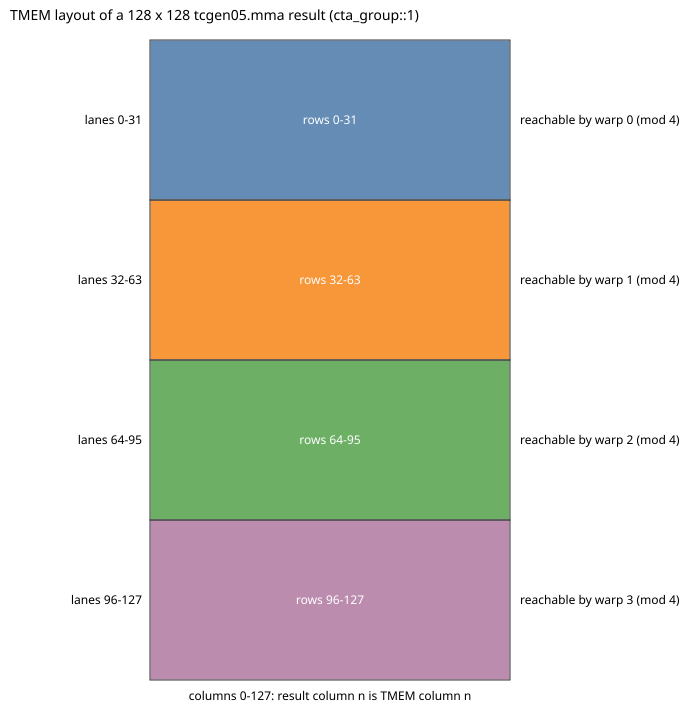

In [6]:
(m, n, two_ctas), = watch1.mma_shapes
print(tmem.accumulator_text(m, n))
booksim.show_svg(tmem.accumulator_svg(m, n))

**Shared-memory bank conflicts.** Shared memory has 32 banks of 4 bytes, and a warp's access that
puts several distinct words in one bank is served in several passes. The simulator counts them for
every shared-memory instruction. (This counter was compared with Nsight Compute on an Ampere GPU for
another kernel, and the conflict counts matched exactly.)

In [7]:
print(booksim.bank_summary(v1))

34 shared-memory instruction(s): 2,053 wavefronts, of which 1,536 are bank conflicts
  line 360: st.shared.b16 [%r21+1024], %rs1;  16 execution(s), 48 conflict(s), worst 4-way
  line 367: st.shared.b16 [%r26+1024], %rs2;  16 execution(s), 48 conflict(s), worst 4-way
  line 374: st.shared.b16 [%r31+1024], %rs3;  16 execution(s), 48 conflict(s), worst 4-way
  ... and 29 more instruction(s) with conflicts


Every staging store conflicts four ways: it puts four distinct words into one bank. Step 2 repeats
these stores for each K tile, and Step 4 replaces them with TMA.

**Findings.** While the kernel ran, the checkers looked for races on shared memory, tensor memory
read before its MMA was committed, operands overwritten under a running MMA, leaked allocations, and
more. They do not depend on the order things happened to run in. For this kernel:

In [8]:
print(f"{len(v1.stats.findings)} finding(s)")
for finding in v1.stats.findings:
    print(finding)

0 finding(s)


**An approximate account of time.** The timing model gives each resource of one SM a rate and plays
the kernel against them. **It is uncalibrated: read the table as an explanation of the mechanism under
the model's assumptions, not as a measurement or a prediction.** Starred entries are assumed values.

Approximate timing on B200 (model, not a measurement)
  1 CTA(s), each alone on one SM; 148 SMs assumed to share HBM
  kernel time 3,923 ns (5,885 clocks at 1.5 GHz, an assumed clock)
  verdict: Tensor Core-bound: the Tensor Core is busy 96% of the time
  resource       busy   derived from
  issue slots     21%   clock_ghz*
  SMEM            35%   smem_wavefront_clk*, clock_ghz*
  TMA engine       0%   tma_bytes_per_clk*, tma_latency_ns*, clock_ghz*
  HBM              0%   hbm_bandwidth_tb_s, active_sms (launch parameter)
  L2               0%   l2_bandwidth_per_sm_gb_s*
  Tensor Core     96%   tensor_core_tflops_f16, tensor_core_tflops_tf32, sm_count, mma_latency_clk, clock_ghz*
  roofline: 12.45 TFLOP/s pipeline rate per SM; compute ceiling 13.04, memory ceiling inf at inf FLOP/byte
  * assumed value in this model; see the config file for every source


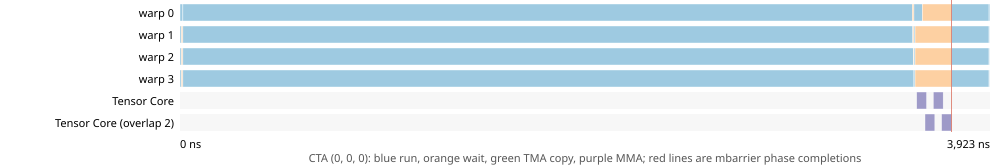

In [9]:
print(v1.stats.timing.summary())
booksim.show_svg(timeline_svg(v1.stats.timing), "(timeline of CTA (0, 0, 0): a picture, shown in Jupyter)")

In the picture each warp has a row (blue while it runs, orange while it waits), the tensor core has
one (purple), and a red line marks an mbarrier phase completing. The four MMAs follow one another on
the tensor core while every warp waits; "Tensor Core-bound" refers to that interval only, which is a
small part of the kernel. Most of the kernel's time is the staging before it and the write-back after.

### Step 2: a loop over K (`hgemm_v2`)

The same tile with K = 256: the kernel now loops over four K tiles and accumulates.

In [10]:
v2, watch2 = run("v2", (128, 128, 256))
static = sum(i.name.startswith("tcgen05.mma") for i in v2.instructions)
executed = sum(counts["MMA"] for counts in watch2.counts.values())
print(f"\ntcgen05.mma instructions in the PTX: {static}; executed: {executed}")
print(watch2.roles())
print(f"\nmodel time, uncalibrated: {v2.stats.timing.time_ns:,.0f} ns; v1 on K = 64 took {v1.stats.timing.time_ns:,.0f} ns")

hgemm_v2 128x128x256: matches NumPy (max error 0.0078, 0.5 s)
grid (1, 1, 1), block (128, 1, 1): 1 CTA(s), 4 warp(s), 33,792 bytes of shared memory per CTA
16,634 warp-instructions executed (528,707 counted per thread), 5 divergent branch(es), 0 finding(s)

tcgen05.mma instructions in the PTX: 4; executed: 16
CTA (0, 0, 0): instructions executed, by warp
  warp  mbarrier wait    MMA  MMA commit  TMEM load  TMEM alloc  TMEM dealloc  SMEM store  SMEM load  barrier  global load  global store
     0              8     16           4          1           1             1         512          2       10          512           128
     1              8      .           .          1           .             .         512          1       10          512           128
     2              8      .           .          1           .             .         512          1       10          512           128
     3              8      .           .          1           .             .         512      

The PTX still holds four MMA instructions. They ran four times each, once per K tile, with the staging
loads and stores before every round: those columns are four times those of Step 1, while the
allocation, the read of the accumulator and the stores of the result happen once. The modeled time
grows by about the same factor, because each round waits for its staging before it can multiply. That
waiting is what the next chapter attacks.

### Step 3: one CTA per output tile (`hgemm_v3`)

A 256 x 256 output is four tiles, so the kernel is launched on a 2 x 2 grid.

In [11]:
v3, watch3 = run("v3", (256, 256, 64))
print("\nCTAs that issued an MMA:", watch3.working_ctas())
print(booksim.changes(v1, v3))

hgemm_v3 256x256x64: matches NumPy (max error 0.0156, 0.6 s)
grid (2, 2, 1), block (128, 1, 1): 4 CTA(s), 16 warp(s), 33,792 bytes of shared memory per CTA
20,252 warp-instructions executed (640,200 counted per thread), 8 divergent branch(es), 0 finding(s)

CTAs that issued an MMA: [(0, 0, 0), (0, 1, 0), (1, 0, 0), (1, 1, 0)]
PTX instruction forms that appear:
  (none)
and that are gone:
  (none)


Nothing new in the instruction set: the kernel differs from Step 1 only in the arithmetic that turns
the CTA's coordinates into a tile's position. In the simulator the four CTAs run one after another,
and in the timing model each is alone on its own SM, so the modeled time of the launch is that of one
tile. Whether memory bandwidth is shared between them is a parameter of the model (`active_sms`), used
below.

## Chapter "Pipelining GEMM with TMA"

### Step 4: TMA loads (`hgemm_v4`)

The staging loads and stores are replaced by TMA: one thread issues a bulk copy from global to shared
memory, and an mbarrier reports when the bytes have arrived.

In [12]:
v4, watch4 = run("v4", (128, 128, 256))
print()
print(booksim.changes(v2, v4))

hgemm_v4 128x128x256: matches NumPy (max error 0.0078, 0.2 s)
grid (1, 1, 1), block (128, 1, 1): 1 CTA(s), 4 warp(s), 66,560 bytes of shared memory per CTA
1,856 warp-instructions executed (55,567 counted per thread), 10 divergent branch(es), 0 finding(s)

PTX instruction forms that appear:
  + cp.async.bulk.commit_group (1)
  + cp.async.bulk.tensor.2d.global.shared::cta.tile.bulk_group (2)
  + cp.async.bulk.tensor.2d.shared::cta.global.tile.mbarrier::complete_tx::bytes (8)
  + cp.async.bulk.wait_group.read (1)
  + mbarrier.arrive.expect_tx.shared.b64 (4)
and that are gone:
  - ld.global.nc.b16 (32)
  - st.global.b16 (128)


The loads and stores on global memory are gone, and with them the kernel's pointer parameters:
`key_instructions` would show three 128-byte structs instead. Those are **tensor maps** passed by value, one each for A, B and
the output. TIRx's runtime asked the CUDA driver to encode them (`cuTensorMapEncodeTiled`); under the
simulator that call is answered by warplens.

New are `cp.async.bulk.tensor` in both directions (the load completes on an mbarrier; the store
belongs to a bulk group that is committed and waited for) and `mbarrier.arrive.expect_tx`, which tells
the mbarrier how many bytes to expect.

This protocol is where the checkers earn their keep. A kernel that reads a tile without waiting for
its mbarrier, expects the wrong number of bytes, or stores with TMA what ordinary stores wrote
without a `fence.proxy.async` in between gets a finding, or a deadlock report that says who waits for
what. This kernel has none:

In [13]:
print(f"{len(v4.stats.findings)} finding(s)")
print(booksim.bank_summary(v4))
print(f"Step 2, same problem: {v2.stats.smem.wavefronts:,} wavefronts, {v2.stats.smem.conflicts:,} conflicts")
print()
print(watch4.order(12, warps=[0]))

0 finding(s)
130 shared-memory instruction(s): 2,053 wavefronts, of which 1,536 are bank conflicts
  line 1206: st.shared.b16 [%r252+33792], %rs1;  4 execution(s), 12 conflict(s), worst 4-way
  line 1207: st.shared.b16 [%r252+33794], %rs2;  4 execution(s), 12 conflict(s), worst 4-way
  line 1208: st.shared.b16 [%r252+33796], %rs3;  4 execution(s), 12 conflict(s), worst 4-way
  ... and 125 more instruction(s) with conflicts
Step 2, same problem: 8,197 wavefronts, 6,144 conflicts

CTA (0, 0, 0): first 12 of 39 asynchronous steps, in the order this run's scheduler took them
  warp  0  TMA load       PTX line 393
  warp  0  TMA load       PTX line 398
  warp  0  mbarrier wait  PTX line 413, 2 times
  warp  0  MMA            PTX line 424
  warp  0  MMA            PTX line 428
  warp  0  MMA            PTX line 431
  warp  0  MMA            PTX line 434
  warp  0  MMA commit     PTX line 439
  warp  0  mbarrier wait  PTX line 450, 2 times
  warp  0  TMA load       PTX line 465
  warp  0  TMA

The steps of warp 0 show the rhythm of this kernel: load a K tile of A and of B, wait for them,
multiply, wait for the multiply, and only then load the next tile.

The bank-conflict totals are a quarter of Step 2's on the same problem, because the staging stores,
which ran once per K tile, no longer exist. The shared-memory stores that remain are new: the result
is now written to shared memory and leaves through a TMA store. They conflict four ways as well.

### Step 5: a two-stage pipeline (`hgemm_v5`)

With two buffers per operand, the loads for the next K tile can be in flight while the current one is
multiplied.

In [14]:
v5, watch5 = run("v5", (128, 128, 256))
print()
print(watch5.order(12, warps=[0]))

hgemm_v5 128x128x256: matches NumPy (max error 0.0078, 0.2 s)
grid (1, 1, 1), block (128, 1, 1): 1 CTA(s), 4 warp(s), 99,328 bytes of shared memory per CTA
1,857 warp-instructions executed (51,601 counted per thread), 9 divergent branch(es), 0 finding(s)

CTA (0, 0, 0): first 12 of 39 asynchronous steps, in the order this run's scheduler took them
  warp  0  TMA load       PTX line 363
  warp  0  TMA load       PTX line 368
  warp  0  TMA load       PTX line 378
  warp  0  TMA load       PTX line 382
  warp  0  mbarrier wait  PTX line 397, 2 times
  warp  0  MMA            PTX line 418
  warp  0  MMA            PTX line 430
  warp  0  MMA            PTX line 441
  warp  0  MMA            PTX line 452
  warp  0  MMA commit     PTX line 456
  warp  0  mbarrier wait  PTX line 468, 2 times
  warp  0  TMA load       PTX line 483


Compare with Step 4: four loads are issued before the first MMA, two tiles' worth. From then on a
load for tile k + 2 goes out as soon as tile k's buffer is free.

What does the timing model make of the change? **Uncalibrated, as before.** The model has a parameter
that matters a great deal here: how many SMs share the memory bandwidth. By default it assumes all
148 are busy, as when a problem fills the device. The second pair of runs assumes 8.

In [15]:
def describe(name, launch):
    t = launch.stats.timing
    u = t.utilization
    return (f"  {name:<28} {t.time_ns:>8,.0f} ns   {t.bottleneck:<12} "
            f"TMA {u['TMA engine']:>4.0%}  HBM {u['HBM']:>4.0%}  Tensor Core {u['Tensor Core']:>4.0%}")


print("model time and verdict (uncalibrated; assumed parameters)")
print(describe("v4, 148 SMs share HBM", v4))
print(describe("v5, 148 SMs share HBM", v5))
for version in ("v4", "v5"):
    done = booksim.run_book_kernel(BOOK, version, (128, 128, 256), timing=True, active_sms=8)
    print(describe(f"{version}, 8 SMs share HBM", done.launch))
print(f"\nshared memory per CTA: v4 {v4.stats.smem_bytes:,} bytes, v5 {v5.stats.smem_bytes:,} bytes")

model time and verdict (uncalibrated; assumed parameters)
  v4, 148 SMs share HBM           8,591 ns   latency      TMA  10%  HBM  69%  Tensor Core   8%
  v5, 148 SMs share HBM           7,739 ns   latency      TMA  11%  HBM  76%  Tensor Core   8%


  v4, 8 SMs share HBM             3,588 ns   latency      TMA  24%  HBM   9%  Tensor Core  18%


  v5, 8 SMs share HBM             2,873 ns   latency      TMA  30%  HBM  11%  Tensor Core  23%

shared memory per CTA: v4 66,560 bytes, v5 99,328 bytes


Read the direction, not the digits. With the whole device assumed busy, one SM's share of memory
bandwidth is the busiest resource for both kernels, and a second stage helps a little. With bandwidth
to spare, the time of a round trip dominates and the pipeline hides more of it. The price is in the last
line: every stage is another pair of buffers in shared memory.

[`examples/04_pipelined_gemm`](../04_pipelined_gemm/run.py) in the warplens repository asks
the same question of a CUDA C++ kernel with 1, 2 and 4 stages.

### Step 6: a persistent kernel with a tile scheduler (`hgemm_v6`)

Instead of one CTA per output tile, the kernel launches one CTA per SM, and each CTA works through the
tiles assigned to it.

In [16]:
v6, watch6 = run("v6", (256, 256, 256))
print("\nCTAs that issued an MMA:", watch6.working_ctas())

hgemm_v6 256x256x256: matches NumPy (max error 0.0312, 1.1 s)
grid (148, 1, 1), block (128, 1, 1): 148 CTA(s), 592 warp(s), 99,328 bytes of shared memory per CTA
23,528 warp-instructions executed (676,392 counted per thread), 180 divergent branch(es), 0 finding(s)

CTAs that issued an MMA: [(0, 0, 0), (1, 0, 0), (2, 0, 0), (3, 0, 0)]


The grid is 148 CTAs, because the simulated device, like a B200, reports 148 SMs. This problem has
four output tiles, so four CTAs find work and 144 start, see there is none, and return. That is the
design, and on a problem that fills the device every CTA would be busy; in a simulator it means the
launch costs 148 CTAs however small the problem.

It also changes how to read the timing model's summary, which averages each resource's utilization
over all CTAs of the launch: here the average is mostly idle CTAs. The modeled kernel time is still
that of the slowest CTA:

In [17]:
print(f"model time, uncalibrated: {v6.stats.timing.time_ns:,.0f} ns for a CTA that computed one of the four tiles")

model time, uncalibrated: 7,743 ns for a CTA that computed one of the four tiles


## Chapter "Scaling GEMM with Warp Specialization and Clusters"

### Step 7: warp specialization (`hgemm_v7`)

The CTA grows to 256 threads, and its warps stop doing the same thing.

In [18]:
v7, watch7 = run("v7")
print()
print(watch7.roles())

hgemm_v7 128x128x256: matches NumPy (max error 0.0078, 2.1 s)
grid (148, 1, 1), block (256, 1, 1): 148 CTA(s), 1184 warp(s), 99,328 bytes of shared memory per CTA
48,258 warp-instructions executed (1,408,119 counted per thread), 151 divergent branch(es), 1 finding(s)

CTA (0, 0, 0): instructions executed, by warp
  warp  TMA load  TMA store  mbarrier arrive  mbarrier wait    MMA  MMA commit  TMEM load  TMEM alloc  TMEM dealloc  SMEM store  SMEM load  barrier  store wait
     0         .          2                1              9      .           .          1           1             1         128          2        4           3
     1         .          .                1              9      .           .          1           .             .         128          1        4           .
     2         .          .                1              9      .           .          1           .             .         128          1        4           .
     3         .          .                1 

The table is the chapter's "warp roles" seen from below. One warp issues every TMA load and never
touches the tensor core. Another issues every MMA and never loads. Warps 0 to 3, a warpgroup, read
the accumulator, write the output tile to shared memory and store it with TMA. The remaining warps
only take part in the barriers.

The roles hand work to each other through mbarriers, which the order of steps shows: the loader and
the multiplier each run their own loop.

CTA (0, 0, 0): first 16 of 91 asynchronous steps, in the order this run's scheduler took them
  warp  0  mbarrier wait  PTX line 1262
  warp  1  mbarrier wait  PTX line 1262
  warp  2  mbarrier wait  PTX line 1262
  warp  3  mbarrier wait  PTX line 1262
  warp  4  mbarrier wait  PTX line 1062
  warp  4  mbarrier wait  PTX line 1075
  warp  7  mbarrier wait  PTX line 948
  warp  7  TMA load       PTX line 960
  warp  7  TMA load       PTX line 965
  warp  7  mbarrier wait  PTX line 976
  warp  7  TMA load       PTX line 987
  warp  7  TMA load       PTX line 991
  warp  7  mbarrier wait  PTX line 1000
  warp  0  mbarrier wait  PTX line 1262
  warp  1  mbarrier wait  PTX line 1262
  warp  2  mbarrier wait  PTX line 1262


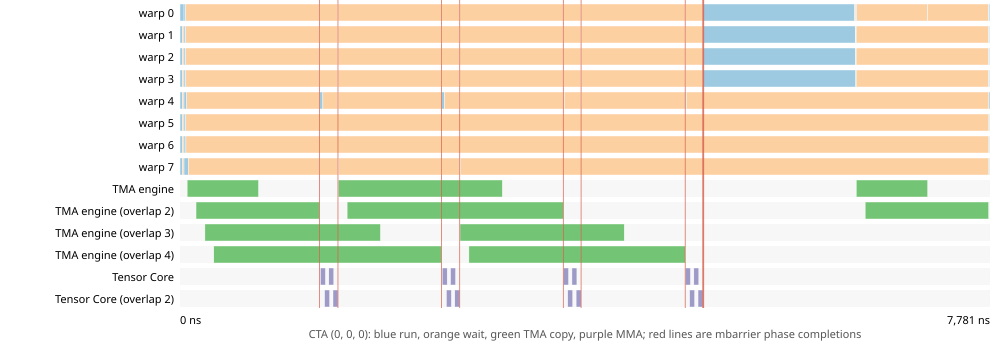

In [19]:
print(watch7.order(16))
booksim.show_svg(timeline_svg(v7.stats.timing), "(timeline of CTA (0, 0, 0): a picture, shown in Jupyter)")

**A finding.** This is the first kernel the checkers remark on:

In [20]:
for finding in v7.stats.findings:
    print(finding)

[tmem-dealloc-repeated] tensor memory at column 0 (512 columns) was already released by an earlier tcgen05.dealloc; this one is ignored (148 times)
  line 2009: tcgen05.dealloc.cta_group::1.sync.aligned.b32 %r275, %r276;
  first in CTA (0, 0, 0), warp 4, lanes 0-31


`tmem-dealloc-repeated`: the kernel's tensor memory is released by more than one warp, and the second
`tcgen05.dealloc` names columns that are already free. The kernel runs on real hardware, so this is
evidently tolerated there, but what a GPU does with the repeated release is not documented and has
not been measured. warplens ignores the repeat and reports it, once per CTA, so that the assumption
is visible. It is on warplens's list of things to check on a B200. `hgemm_v8` and `hgemm_v9` do the
same.

This is the kind of thing a simulator is for: the kernel's result is correct here and on hardware,
and the finding is still worth knowing about.

### Step 8: a cluster of two CTAs (`hgemm_v8`)

Two CTAs on neighbouring SMs form a cluster and share one MMA of twice the height.

In [21]:
v8, watch8 = run("v8")
print()
print(booksim.changes(v7, v8))

hgemm_v8 256x256x256: matches NumPy (max error 0.0156, 3.4 s)
grid (148, 1, 1), block (256, 1, 1), clusters of (2, 1, 1): 148 CTA(s), 1184 warp(s), 164,864 bytes of shared memory per CTA
67,221 warp-instructions executed (1,971,604 counted per thread), 155 divergent branch(es), 1 finding(s)

PTX instruction forms that appear:
  + barrier.cluster.arrive.aligned (1)
  + barrier.cluster.wait.aligned (1)
  + cp.async.bulk.tensor.2d.shared::cluster.global.tile.mbarrier::complete_tx::bytes.cta_group::2 (8)
  + mapa.u64 (2)
  + mbarrier.arrive.expect_tx.shared::cluster.b64 (4)
  + mbarrier.arrive.shared::cluster.b64 (1)
  + tcgen05.alloc.cta_group::2.sync.aligned.shared::cta.b32 (1)
  + tcgen05.commit.cta_group::2.mbarrier::arrive::one.shared::cluster.multicast::cluster.b64 (5)
  + tcgen05.dealloc.cta_group::2.sync.aligned.b32 (1)
  + tcgen05.mma.cta_group::2.kind::f16 (16)
  + tcgen05.relinquish_alloc_permit.cta_group::2.sync.aligned (1)
and that are gone:
  - cp.async.bulk.tensor.2d.shared:

Everything in the list is the cluster at work: `cta_group::2` forms of the MMA, the allocation and
the commit; TMA loads that deliver to shared memory of the cluster and count bytes on a peer's
mbarrier; `mapa`, which turns a shared-memory address into the same location in the other CTA;
`mbarrier.arrive` on such an address; a cluster-wide barrier; and a commit that arrives on mbarriers
of both CTAs at once (`multicast::cluster`).

Who does what, in the two CTAs of the first cluster:

In [22]:
print(watch8.roles((0, 0, 0)))
print()
print(watch8.roles((1, 0, 0)))

CTA (0, 0, 0): instructions executed, by warp
  warp  TMA load  TMA store  mbarrier arrive  mbarrier wait    MMA  MMA commit  TMEM load  TMEM alloc  TMEM dealloc  SMEM store  SMEM load  barrier  store wait
     0         .          4                1              9      .           .          2           1             1         256          2        7           6
     1         .          .                1              9      .           .          2           .             .         256          1        7           .
     2         .          .                1              9      .           .          2           .             .         256          1        7           .
     3         .          .                1              9      .           .          2           .             .         256          1        7           .
     4         .          .                .             12     16           5          .           .             1           .          2        3       

Only the first CTA issues MMAs. Each CTA loads its own half of the operands into its own shared
memory, and one `tcgen05.mma` in the first CTA reads both halves and writes half of the result into
each CTA's tensor memory, where that CTA's write-back warps pick it up:

In [23]:
(m, n, two_ctas), = watch8.mma_shapes
print(tmem.pair_text(m, n) if two_ctas else tmem.accumulator_text(m, n))

TMEM layout of a 256 x 256 tcgen05.mma result (cta_group::2)
  CTA    lanes      holds
  even   0-127      rows 0-127, columns 0-255 in TMEM columns 0-255
  odd    0-127      rows 128-255, columns 0-255 in TMEM columns 0-255


### Step 9: two MMA consumers (`hgemm_v9`)

The cluster's tile grows to 512 x 256, computed as two 256 x 256 halves by two MMA warps.

In [24]:
v9, watch9 = run("v9")
print()
print(watch9.roles((0, 0, 0)))
limit = 228 * 1024
print(f"\nshared memory per CTA: {v9.stats.smem_bytes:,} of the {limit:,} bytes a CTA can have")

hgemm_v9 512x256x256: matches NumPy (max error 0.0312, 4.3 s)
grid (148, 1, 1), block (384, 1, 1), clusters of (2, 1, 1): 148 CTA(s), 1776 warp(s), 230,400 bytes of shared memory per CTA
102,713 warp-instructions executed (3,067,573 counted per thread), 168 divergent branch(es), 1 finding(s)

CTA (0, 0, 0): instructions executed, by warp
  warp  TMA load  TMA store  mbarrier arrive  mbarrier wait    MMA  MMA commit  TMEM load  TMEM alloc  TMEM dealloc  SMEM store  SMEM load  barrier  store wait
     0         .          4                1              9      .           .          4           1             1         256          2       11           8
     1         .          .                1              9      .           .          4           .             .         256          1       11           .
     2         .          .                1              9      .           .          4           .             .         256          1       11           .
     3         .    

Two warps now issue MMAs, each with its own commits and waits, fed by one loader, and two warpgroups
write back. The last line is the other thing this step spends: its buffers take nearly all the shared
memory a CTA can have on this architecture.

## The nine kernels side by side

Each on the problem it was run on above. The time column is the timing model's and is
**uncalibrated**; the problems differ in size, so compare it only between rows of the same size.

In [25]:
print("kernel  grid   block  SMEM bytes/CTA  warp-instructions  model time (uncalibrated)  findings")
for version in sorted(launches):
    launch, s = launches[version], launches[version].stats
    kinds = ", ".join(sorted({f.kind for f in s.findings})) or "none"
    grid = "x".join(str(g) for g in launch.grid if g > 1) or "1"
    print(f"{version:<7} {grid:<6} {launch.block[0]:>5}  {s.smem_bytes:>14,}  {s.instructions:>17,}  "
          f"{s.timing.time_ns:>22,.0f} ns  {kinds}")

kernel  grid   block  SMEM bytes/CTA  warp-instructions  model time (uncalibrated)  findings
v1      1        128          33,792              5,011                   3,923 ns  none
v2      1        128          33,792             16,634                  15,098 ns  none
v3      2x2      128          33,792             20,252                   3,932 ns  none
v4      1        128          66,560              1,856                   8,591 ns  none
v5      1        128          99,328              1,857                   7,739 ns  none
v6      148      128          99,328             23,528                   7,743 ns  none
v7      148      256          99,328             48,258                   7,781 ns  tmem-dealloc-repeated
v8      148      256         164,864             67,221                  11,031 ns  tmem-dealloc-repeated
v9      148      384         230,400            102,713                  15,495 ns  tmem-dealloc-repeated


## Where to go from here

- Change a size and run a cell again: `run("v5", (128, 128, 512))`. Each kernel has a smallest
  problem it does any work on; the runner's defaults are those.
- `launch.stats.smem.format()` is the full bank-conflict table of a launch, `launch.stats.report()`
  adds the findings, and `launch.stats.timing.write_html("report.html")` writes the timing report
  with every parameter and its source. `launch.stats.timing.write_trace("run.trace.json")` writes a
  trace for [ui.perfetto.dev](https://ui.perfetto.dev).
- To see the checkers catch real mistakes, run `python examples/02_tma_copy/run.py` in the warplens
  repository: a TMA kernel with five deliberate bugs.
- The [user guide](../../docs/guide.md) covers the other ways to get code into the simulator (CUDA C++,
  Triton, the CuTe DSL), every kind of finding, and the limits. The book's other chapters are not
  covered here; its FlashAttention kernels have not been tried in warplens.